In [2]:
%load_ext autoreload
%autoreload 2
import numpy as np
import emcee
import corner
from matplotlib import pyplot as plt
from astropy import units as u
from astropy import constants as const
import time
from multiprocessing import Pool

from nfw_profile_heating import NFWProfile
from cluster_error_prop import Cluster_werr
from statistics_functions import log_lik
from load_data_and_var import load_data_and_var, generate_nfws_from_combined_dataset_werr
from plotting import savefig, paper_plot

In [3]:
dataset, variances = load_data_and_var()

/Users/eleanorstuart/Desktop/krisp/thermo-idm/load_data_and_var.py:14: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  low_z_data = comb_data[comb_data['z_y'] < 0.2][comb_data['Sub-Cat']=='REFLEX'][['OName',


In [420]:
nfws_werr = generate_nfws_from_combined_dataset_werr(dataset, variances)

In [421]:
nfws= [nfw for nfw in nfws_werr if nfw.energies.is_virialized_gaspari]
len(nfws)

111

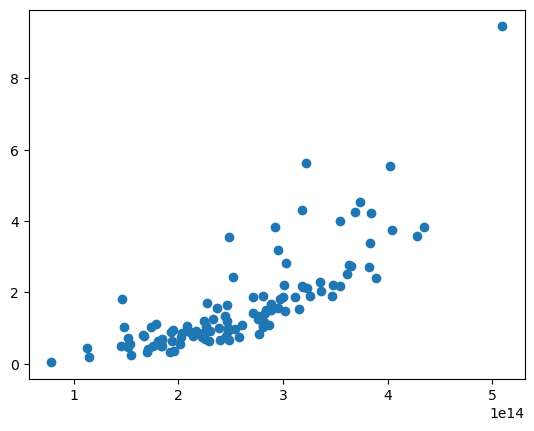

In [422]:
plt.scatter([nfw.M500 for nfw in nfws],[nfw.L500 for nfw in nfws])

In [423]:
test_nfw=nfws[0]

In [424]:
test_nfw.L_indep_factors

array([7.41841576e+78, 7.87357381e+78, 7.54462852e+78, 7.23062966e+78,
       6.93103248e+78, 6.64532408e+78, 6.37302224e+78, 6.11367428e+78,
       5.86685570e+78, 5.63216851e+78, 5.40923922e+78, 5.19771642e+78,
       4.99726757e+78, 4.80757503e+78, 4.62833108e+78, 4.45923146e+78,
       4.29996745e+78, 4.15021586e+78, 4.00962681e+78, 3.87780884e+78,
       3.75431117e+78, 3.63860299e+78, 3.53004982e+78, 3.42788754e+78,
       3.33119513e+78, 3.23886784e+78, 3.14959378e+78, 3.06183782e+78,
       2.97383818e+78, 2.88362238e+78, 2.78904994e+78, 2.68788945e+78,
       2.57793625e+78, 2.45717324e+78, 2.32397166e+78, 2.17731978e+78,
       2.01705624e+78, 1.84407430e+78, 1.66045388e+78, 1.46947703e+78,
       1.27549056e+78, 1.08360091e+78, 8.99219077e+77, 7.27510961e+77,
       5.72840812e+77, 4.38309806e+77, 3.25479711e+77, 2.34332839e+77,
       1.63464251e+77, 1.35119826e+77])

In [179]:
range(-40, -25)

range(-40, -25)

0.5853001790934521
0.5853001790935195
0.5853001790942017
0.585300179101024
0.5853001791692424
0.5853001798514258
0.5853001866732511
0.5853002548915124
0.5853009370741704
0.5853077589073562
0.5853759778974211
0.586058233624999
0.5928873801536845
0.6618443504262493
1.424594397311215


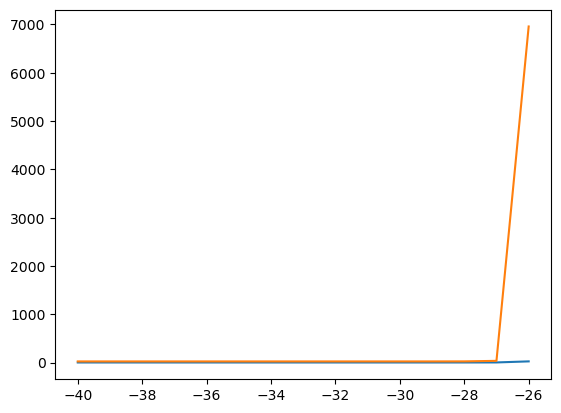

In [182]:
plt.plot([s for s in range(-40, -25)], [test_nfw.L500_numerical(1e-2, 10**s) for s in range(-40, -25)])

In [17]:
test_nfw.L500.value, test_nfw.L_err

(0.846881, 0.136706611275864)

In [470]:
p0=[-27, -2]
obs = [n.L500.value for n in nfws]

In [510]:
variances = np.array([n.L_err for n in nfws])

In [513]:
import cProfile
import pstats

profiler = cProfile.Profile()
profiler.enable()

print(log_lik(p0, obs, nfws, variances))

profiler.disable()
stats = pstats.Stats(profiler).sort_stats('cumtime')
stats.print_stats()

-35.73657735978669
         125466 function calls in 0.241 seconds

   Ordered by: cumulative time

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        2    0.000    0.000    0.241    0.120 /Users/eleanorstuart/opt/anaconda3/envs/idm/lib/python3.11/site-packages/IPython/core/interactiveshell.py:3490(run_code)
        2    0.000    0.000    0.241    0.120 {built-in method builtins.exec}
        1    0.000    0.000    0.241    0.241 /Users/eleanorstuart/Desktop/krisp/thermo-idm/statistics_functions.py:37(log_lik)
        1    0.000    0.000    0.240    0.240 /Users/eleanorstuart/Desktop/krisp/thermo-idm/statistics_functions.py:68(<listcomp>)
      111    0.003    0.000    0.239    0.002 /Users/eleanorstuart/Desktop/krisp/thermo-idm/cluster_error_prop.py:473(L500_numerical)
      333    0.001    0.000    0.234    0.001 /Users/eleanorstuart/opt/anaconda3/envs/idm/lib/python3.11/site-packages/scipy/optimize/_zeros_py.py:672(brentq)
      333    0.002    0.000    

In [224]:
net_heating, net_heating_min, net_heating_max = test_nfw.L500_numerical(1e-2, 1e-30)

Text(0, 0.5, 'net heating rate (erg/s)')

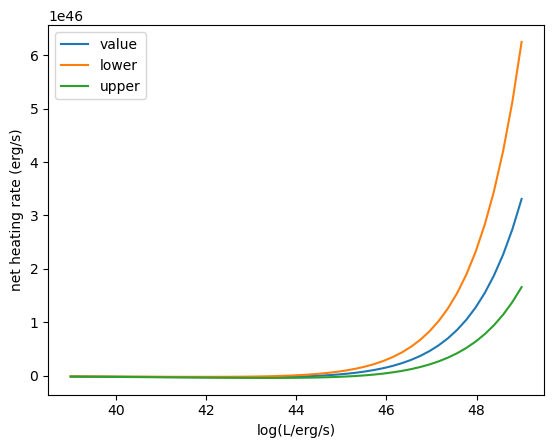

In [230]:
plt.plot(np.linspace(-5, 5)+44, net_heating, label='value')
plt.plot(np.linspace(-5, 5)+44, net_heating_min, label='lower')
plt.plot(np.linspace(-5, 5)+44, net_heating_max, label='upper')
plt.legend()
plt.xlabel('log(L/erg/s)')
plt.ylabel('net heating rate (erg/s)')
#

Text(0, 0.5, 'net heating rate (erg/s)')

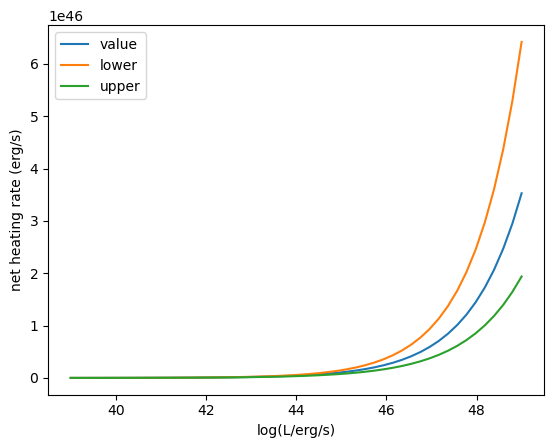

In [232]:
net_heating, net_heating_min, net_heating_max = test_nfw.L500_numerical(1e-2, 1e-30)
plt.plot(np.linspace(-5, 5)+44, net_heating, label='value')
plt.plot(np.linspace(-5, 5)+44, net_heating_min, label='lower')
plt.plot(np.linspace(-5, 5)+44, net_heating_max, label='upper')
plt.legend()
plt.xlabel('log(L/erg/s)')
plt.ylabel('net heating rate (erg/s)')

Text(0, 0.5, 'net heating rate (erg/s)')

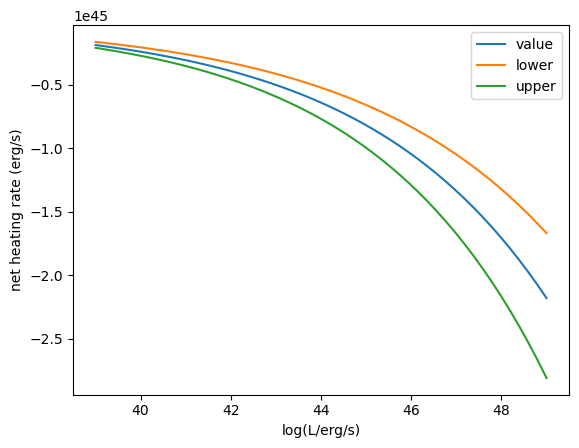

In [234]:
net_heating, net_heating_min, net_heating_max = test_nfw.L500_numerical(1e-2, 1e-30)
plt.plot(np.linspace(-5, 5)+44, net_heating, label='value')
plt.plot(np.linspace(-5, 5)+44, net_heating_min, label='lower')
plt.plot(np.linspace(-5, 5)+44, net_heating_max, label='upper')
plt.legend()
plt.xlabel('log(L/erg/s)')
plt.ylabel('net heating rate (erg/s)')

In [235]:
from cluster_error_prop import Linj_from_L500

Text(0, 0.5, 'logLinj (erg/s)')

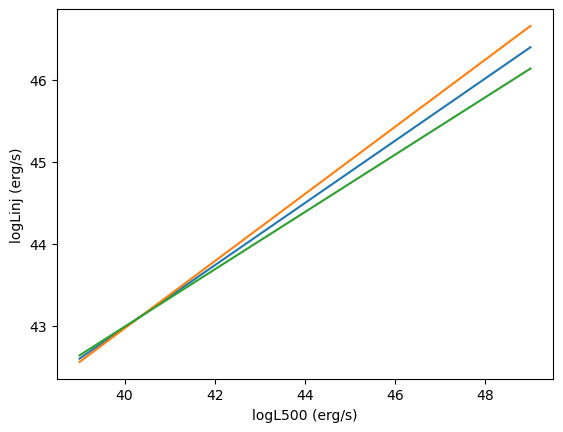

In [242]:
plt.plot(np.linspace(-5, 5)+44, np.log10(Linj_from_L500(np.linspace(-5, 5))))
plt.plot(np.linspace(-5, 5)+44, np.log10(Linj_from_L500(np.linspace(-5, 5), bound='max')))
plt.plot(np.linspace(-5, 5)+44, np.log10(Linj_from_L500(np.linspace(-5, 5), bound='min')))
plt.xlabel('logL500 (erg/s)')
plt.ylabel('logLinj (erg/s)')
#plt.yscale('log')

In [514]:
import numpy as np

# Create linearly spaced values from -40 to -30
s0_linear = np.linspace(-40, -29, 10)

# Create exponentially spaced values from -30 to -25
s0_exponential = -28 + np.geomspace(1, 5, 20) - 1

# Combine the arrays
s0_combined = np.concatenate((s0_linear, s0_exponential))

# Create the list of p0
p0_list = [[s0, -2] for s0 in s0_combined]

print(p0_list)

[[-40.0, -2], [-38.77777777777778, -2], [-37.55555555555556, -2], [-36.333333333333336, -2], [-35.111111111111114, -2], [-33.888888888888886, -2], [-32.666666666666664, -2], [-31.444444444444443, -2], [-30.22222222222222, -2], [-29.0, -2], [-28.0, -2], [-27.911601599269613, -2], [-27.815388921287536, -2], [-27.710671196441854, -2], [-27.59669659219169, -2], [-27.472646815201934, -2], [-27.33763123631532, -2], [-27.190680496181443, -2], [-27.030739545633587, -2], [-26.856660070846, -2], [-26.667192248887204, -2], [-26.460975774477383, -2], [-26.236530093525474, -2], [-25.99224377332657, -2], [-25.726362933101775, -2], [-25.436978651816258, -2], [-25.122013262868588, -2], [-24.779205437252518, -2], [-24.406093948094124, -2], [-24.0, -2]]


In [479]:
s0_combined

array([-40.        , -38.55555556, -37.11111111, -35.66666667,
       -34.22222222, -32.77777778, -31.33333333, -29.88888889,
       -28.44444444, -27.        , -26.        , -25.94047394,
       -25.87740452, -25.81058083, -25.73977938, -25.66476341,
       -25.58528203, -25.50106944, -25.411844  , -25.31730732,
       -25.21714325, -25.1110168 , -24.99857307, -24.879436  ,
       -24.75320717, -24.61946443, -24.47776052, -24.32762153,
       -24.16854535, -24.        ])

In [517]:
var = np.array([n.L_err for n in nfws])
log_liks = [log_lik(p, obs, nfws, var) for p in p0_list]
log_liks

[-0.7918183229935916,
 -0.7918183229931347,
 -0.7918183229855021,
 -0.7918183228581862,
 -0.7918183207344338,
 -0.7918182853081428,
 -0.7918176943621308,
 -0.7918078368404078,
 -0.7916434178986458,
 -0.7889047576986847,
 -0.763065897278233,
 -0.7566923192944123,
 -0.7481772315760947,
 -0.736618061190531,
 -0.7206693163397258,
 -0.6983113914105297,
 -0.6665172658426909,
 -0.620833315623019,
 -0.5550670038436775,
 -0.4618731847079629,
 -0.3366731740336134,
 -0.18992256476893207,
 -0.0653651343441029,
 -0.011354017124146997,
 -0.0009018830185462807,
 -2.429864617620359e-09,
 -6.809296303728507e-49,
 -inf,
 -inf,
 -inf]

Text(0.5, 1.0, 'log likelihood without variance on scaling relations')

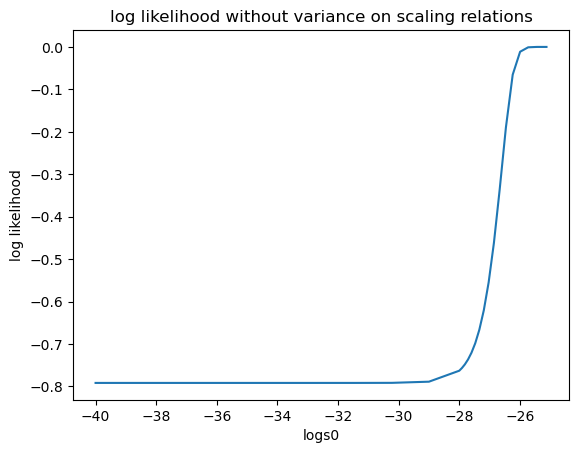

In [518]:
plt.plot(s0_combined, log_liks)
plt.xlabel('logs0')
plt.ylabel('log likelihood')


plt.title('log likelihood without variance on scaling relations')

outside prior
outside prior
outside prior


Text(0.5, 1.0, 'log likelihood with variance on scaling relations')

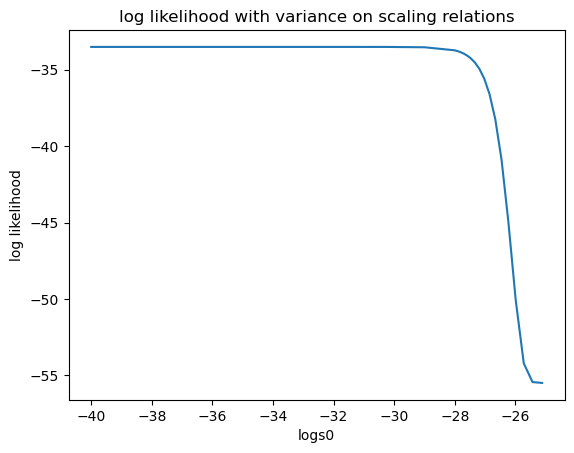

In [501]:
log_liks2 = [log_lik(p, obs, nfws) for p in p0_list]
log_liks2
plt.plot(s0_combined, log_liks2)
plt.xlabel('logs0')
plt.ylabel('log likelihood')


plt.title('log likelihood with variance on scaling relations')

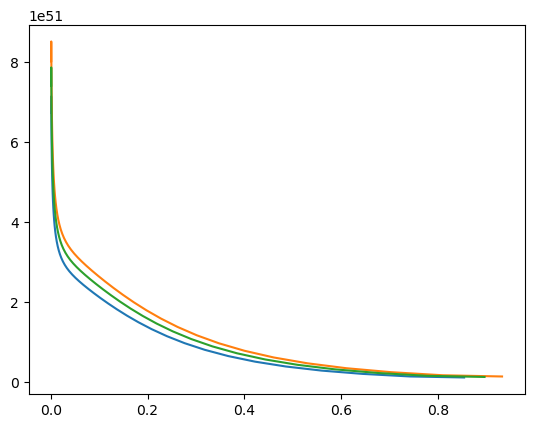

In [382]:
plt.plot(test_nfw.precalc.rs_min,test_nfw.precalc.L_indep_factors_min*1e-27)
plt.plot(test_nfw.precalc.rs_max,test_nfw.precalc.L_indep_factors_max*1e-27)
plt.plot(test_nfw.rs_Mpc, test_nfw.L_indep_factors*1e-27)

In [387]:
print( np.trapz( test_nfw.L_indep_factors*1e-30*(np.sqrt(test_nfw.Tbs)), test_nfw.rs_Mpc))

2.03483500618578e+45 (+2.747082367460992e+44, -2.7581599246054692e+44)


In [391]:
print( np.trapz( test_nfw.precalc.L_indep_factors_min*1e-30*(np.sqrt(test_nfw.Tbs)), test_nfw.precalc.rs_min))

1.7559218135589994e+45 (+8.710819695594774e+43, -8.704438050265718e+43)


In [390]:
print( np.trapz( test_nfw.precalc.L_indep_factors_max*1e-30*(np.sqrt(test_nfw.Tbs)),test_nfw.precalc.rs_max))

2.2965440259260847e+45 (+1.1369143513096356e+44, -1.1360755040445824e+44)


In [466]:
s0_values = np.logspace(-30,-24, 20)
s0_values

array([1.00000000e-30, 2.06913808e-30, 4.28133240e-30, 8.85866790e-30,
       1.83298071e-29, 3.79269019e-29, 7.84759970e-29, 1.62377674e-28,
       3.35981829e-28, 6.95192796e-28, 1.43844989e-27, 2.97635144e-27,
       6.15848211e-27, 1.27427499e-26, 2.63665090e-26, 5.45559478e-26,
       1.12883789e-25, 2.33572147e-25, 4.83293024e-25, 1.00000000e-24])

In [467]:
test_nfw.L_indep_factors

array([7.41841576e+78, 7.87357381e+78, 7.54462852e+78, 7.23062966e+78,
       6.93103248e+78, 6.64532408e+78, 6.37302224e+78, 6.11367428e+78,
       5.86685570e+78, 5.63216851e+78, 5.40923922e+78, 5.19771642e+78,
       4.99726757e+78, 4.80757503e+78, 4.62833108e+78, 4.45923146e+78,
       4.29996745e+78, 4.15021586e+78, 4.00962681e+78, 3.87780884e+78,
       3.75431117e+78, 3.63860299e+78, 3.53004982e+78, 3.42788754e+78,
       3.33119513e+78, 3.23886784e+78, 3.14959378e+78, 3.06183782e+78,
       2.97383818e+78, 2.88362238e+78, 2.78904994e+78, 2.68788945e+78,
       2.57793625e+78, 2.45717324e+78, 2.32397166e+78, 2.17731978e+78,
       2.01705624e+78, 1.84407430e+78, 1.66045388e+78, 1.46947703e+78,
       1.27549056e+78, 1.08360091e+78, 8.99219077e+77, 7.27510961e+77,
       5.72840812e+77, 4.38309806e+77, 3.25479711e+77, 2.34332839e+77,
       1.63464251e+77, 1.35119826e+77])

In [564]:
L_sols = [test_nfw.L500_numerical(1e-2, s)[0] for s in s0_values]
L_vars = [test_nfw.L500_numerical(1e-2, s)[1] for s in s0_values]

Text(0, 0.5, 'L (1e44 erg/s)')

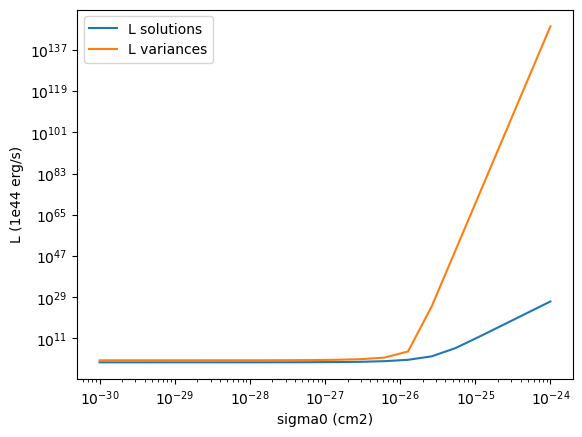

In [565]:
plt.plot(s0_values, L_sols, label='L solutions')
plt.plot(s0_values, L_vars, label='L variances')
plt.xscale('log')
plt.yscale('log')
plt.legend()
plt.xlabel('sigma0 (cm2)')
plt.ylabel('L (1e44 erg/s)')

In [363]:
test_nfw.precalc.rad_factors_min

9.139833002873618e+40

In [543]:
Ls = np.linspace(-10, 10)
net, net_min, net_max = test_nfw.L500_numerical(1e-2, 1e-27)

Text(0, 0.5, 'net heating erg/s')

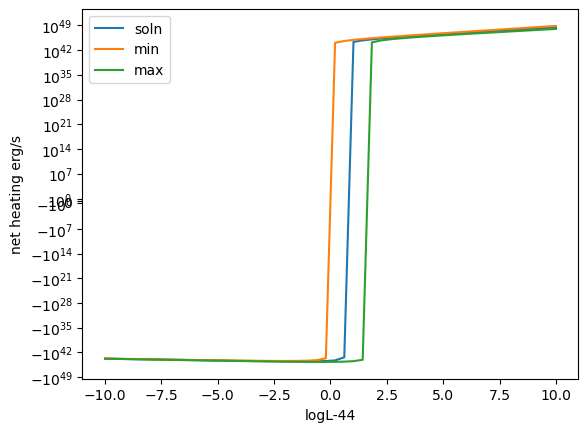

In [546]:
plt.plot(Ls, net, label="soln")
plt.plot(Ls, net_min, label='min')
plt.plot(Ls, net_max, label='max')
plt.legend()
plt.yscale('symlog')
plt.xlabel('logL-44')
plt.ylabel('net heating erg/s')

Text(0, 0.5, 'net heating erg/s')

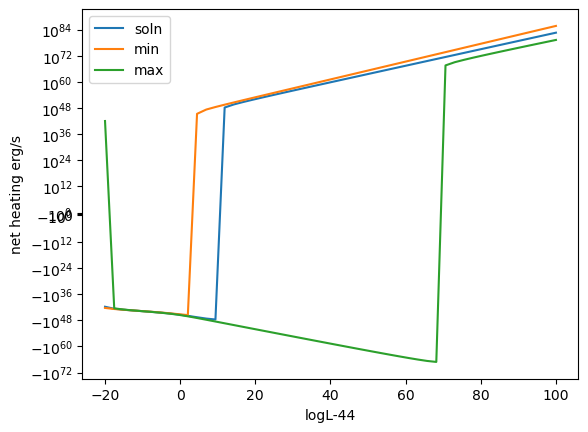

In [554]:
Ls = np.linspace(-20, 100)
net, net_min, net_max = test_nfw.L500_numerical(1e-2, 1e-25)
plt.plot(Ls, net, label="soln")
plt.plot(Ls, net_min, label='min')
plt.plot(Ls, net_max, label='max')
plt.legend()
plt.yscale('symlog')
plt.xlabel('logL-44')
plt.ylabel('net heating erg/s')

Text(0, 0.5, 'net heating erg/s')

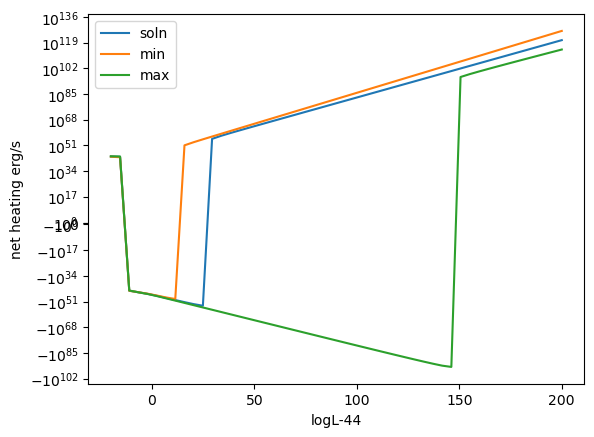

In [556]:
Ls = np.linspace(-10, 250)
net, net_min, net_max = test_nfw.L500_numerical(1e-2, 1e-24)
plt.plot(Ls, net, label="soln")
plt.plot(Ls, net_min, label='min')
plt.plot(Ls, net_max, label='max')
plt.legend()
plt.yscale('symlog')
plt.xlabel('logL-44')
plt.ylabel('net heating erg/s')

Text(0, 0.5, 'net heating erg/s')

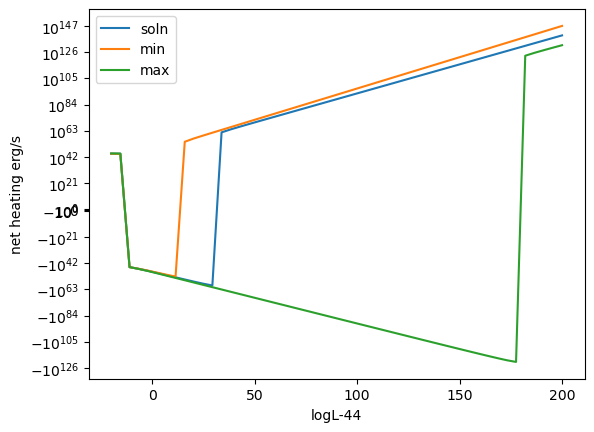

In [558]:
Ls = np.linspace(-10, 250)
net, net_min, net_max = test_nfw.L500_numerical(1e-2, 1e-23)
plt.plot(Ls, net, label="soln")
plt.plot(Ls, net_min, label='min')
plt.plot(Ls, net_max, label='max')
plt.legend()
plt.yscale('symlog')
plt.xlabel('logL-44')
plt.ylabel('net heating erg/s')